# Case study with tree-based models (10pts)
# Introduction
Smoking has long been known as an activity detrimental to health. According to the [CDC](https://archive.cdc.gov/#/details?q=smoking&start=0&rows=10&url=https://www.cdc.gov/vitalsigns/adultsmoking/index.html), smoking is carcinogenic and can cause harm to nearly every organ in the body. By analyzing the variation in biological features associated with smoking, we can better understand the mechanisms through which smoking causes harm and identify individuals with the highest risk factors.

# Overview
In this assignment, we will apply and compare decision tree and random forest classifiers to predict an individual's smoking status. We will also create a decision tree regressor and compare it with the classifier. The [dataset](https://www.kaggle.com/datasets/gauravduttakiit/smoker-status-prediction) for this assignment contains 22 individial biological features and an indicator for smoking status.


# Goals

1) Implement and fine-tune a decision tree classifier to predict an indivudal's smoking status

2) Use the structure of the decision tree to better understand the relationship between the biological factors and smoking

3) Understand the pros and cons of decision trees

4) Implement a random forest classifier and compare the results with those of the decision tree classifier

5) Implement a decision tree regressor and briefly compare it with the decision tree classifier

# Data Overview

**Target variable:**
- smoking: dummy, smoking status of the person, 1 represents smoker, 0 for non-smoker

**Continuous/Numeric variables:**
- age: integer, the age of the person
- height(cm): integer, the height of the person in centimeter
- weight(kg): integer, the weight of the person in kilogram
- waist(cm): integer, the waist of the person in centimeter
- eyesight(left): float, the left eyesight of the person, range 0-10
- eyesight(right): float, the left eyesight of the person, range 0-10
- systolic: integer, systolic blood pressure, the pressure in the arteries during ventricular contraction, normal range 90-120
- relaxation: integer, diastolic blood pressure, the pressure in the arteries during ventricular relaxation, normal range 60-80
- fasting blood sugar: integer, fasting blood sugar, healthy range < 125 mg/dL, high > 126 mg/dL
- Cholesterol: integer, total cholesterol level, high cholesterol could be caused by smoking or other unhealthy habits/diseaces, healthy range < 240 mg/dL, high > 240 mg/dL
- triglyceride: integer, triglyceride level, high triglycerides is a sign of increasing risk of heart disease. Healthy range < 200 mg/dL, high 201-500 mg/dL
- HDL: integer, HDL (high-density lipoprotein) cholesterol, high levels of HDL cholesterol can lower the risk for heart disease and stroke. Normal range > 40 mg/dL
- LDL: integer, LDL (low-density lipoprotein) cholesterol, high levels of LDL cholesterol raise the risk for heart disease and stroke. Normal range < 159 mg/dL
- hemoglobin: integer, measures the amount of hemoglobin in your blood, high hemoglobin level is usually a result of smoking, normal range 12.1 to 17.2 g/dL
- serum creatinine: float, the amount of creatinine in blood,  can be used to estimate how quickly the kidneys filter blood (glomerular filtration rate). Normal range 0.59 to 1.35 mg/dL.
- AST: integer, measures the level of AST enzyme in the blood, an increased AST level is often a sign of liver disease. Normal range 8 to 33 U/L.
- ALT: integer, measures the level of ALT enzyme, found mainly in the liver, in blood. Normal range 4 to 36 U/L.
- Gtp: integer, measures the amount of GTP enzyme in the blood, high diseases. Normal range 5 to 40 U/L.



**Categorical variables:**
- hearing(left): dummy, the left year hearing capacity of the person, 1 represents normal hearing, 0 for disability in hearing
- hearing(right): dummy, the right year hearing capacity of the person, same as hearing(left)
- Urine protein: integer, range from 1 to 6, protein level in urine, normal range <= 1
- dental caries: dummy, dental caries (tooth decay) of the person, 1 represents having tooth decay, usually associated with smoking, 0 represents no tooth decay


In [1]:
# machine learning and visualization libraries
import os
import numpy as np
import pandas as pd

from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

import seaborn as sns
import graphviz
import matplotlib.pyplot as plt
%matplotlib inline

# Import data and conduct exploratory data analysis

In [2]:
# Import data
data_path = "./smoking status/" # change this to your path
df = pd.read_csv(os.path.join(data_path, 'train_dataset.csv'))

# Check (#samples, #features)
df.shape

(38984, 23)

In [3]:
# View variables
print(df.columns)

Index(['age', 'height(cm)', 'weight(kg)', 'waist(cm)', 'eyesight(left)',
       'eyesight(right)', 'hearing(left)', 'hearing(right)', 'systolic',
       'relaxation', 'fasting blood sugar', 'Cholesterol', 'triglyceride',
       'HDL', 'LDL', 'hemoglobin', 'Urine protein', 'serum creatinine', 'AST',
       'ALT', 'Gtp', 'dental caries', 'smoking'],
      dtype='object')


In [4]:
# check some samples
df.head()

,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,...,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,smoking
0,35,170,85,97.0,0.9,0.9,1,1,118,78,...,70,142,19.8,1,1.0,61,115,125,1,1
1,20,175,110,110.0,0.7,0.9,1,1,119,79,...,71,114,15.9,1,1.1,19,25,30,1,0
2,45,155,65,86.0,0.9,0.9,1,1,110,80,...,57,112,13.7,3,0.6,1090,1400,276,0,0
3,45,165,80,94.0,0.8,0.7,1,1,158,88,...,46,91,16.9,1,0.9,32,36,36,0,0
4,20,165,60,81.0,1.5,0.1,1,1,109,64,...,47,92,14.9,1,1.2,26,28,15,0,0


## Explore target variable

Target variable: smoking

The aim here is to better understand our target and verify its integrity. We will look at some summary statistics, empirical distribution and missing values.

In [5]:
print(df.smoking.describe()) # summary statistics
print()
print("Number of missing values: {}".format(df.smoking.isna().sum())) 
print("Proportion of missing values: {:.4f}".format(df.smoking.isna().sum()/len(df)))

count    38984.000000
mean         0.367279
std          0.482070
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          1.000000
Name: smoking, dtype: float64

Number of missing values: 0
Proportion of missing values: 0.0000


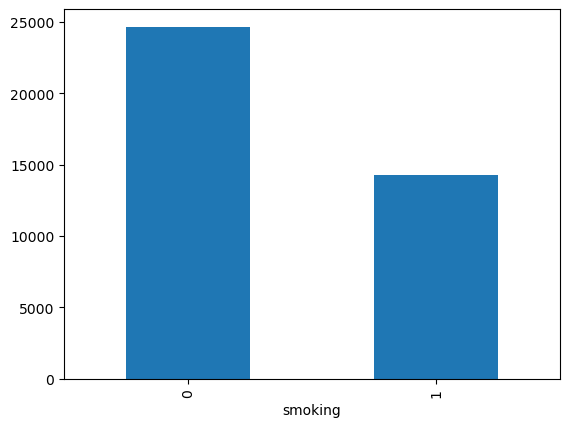

In [6]:
# Plot histogram of the target variable, 0 is not smoking and 1 is smoking
df.smoking.value_counts().plot(kind='bar');

According to this plot, we observe that this dataset contains more non-smokers than smokers. 

## Explore Features

We will now explore our features by:

1) Check for missing values

2) Exploratory data analysis

### Missing values

In [7]:
# Check missing values
null_share = df.isna().sum()/len(df)
#filters the null_share Series to include only the entries where the share of null values is greater than 0.
null_share[null_share>0]

Series([], dtype: float64)

We can see there are no missing values.

### Exploratory data analysis

In [8]:
# Collect feature columns and exclude the target varibale
cols_keep = df.columns[0:-1] #selects all column names except for the last one
data = df.loc[:, cols_keep]
print(data.shape)

(38984, 22)


Using the prior knowledge of the features (described in the data overview), let's first encode the **categorical features**

In [9]:
# Collect categorical features and check the category distribution of each feature
cats = ['hearing(left)', 'hearing(right)', 'Urine protein', 'dental caries']

In [10]:
data['hearing(left)'].value_counts()

hearing(left)
1    37995
2      989
Name: count, dtype: int64

In [11]:
data['hearing(right)'].value_counts()

hearing(right)
1    37963
2     1021
Name: count, dtype: int64

In [12]:
data['Urine protein'].value_counts()

Urine protein
1    36836
2     1236
3      667
4      182
5       58
6        5
Name: count, dtype: int64

In [13]:
data['dental caries'].value_counts()

dental caries
0    30625
1     8359
Name: count, dtype: int64

- Encode categorical features
     - We will apply one-hot encoder to encode categorical features here <br>
     - Later on, we will have an additional discussion about **whether it is necessary** to encode categorical features and if we don't encode categorical features, how will this affect model performance.


In [14]:
# Initiate one-hot encoder
ohe = OneHotEncoder(handle_unknown='ignore')
ohe.fit(data[cats]) 

# encode the features with the learned categories during the fit process
ohe_features = pd.DataFrame(ohe.transform(data[cats]).toarray())
print(ohe_features)

# rename columns so we can analyze them later
col_names = []
for i in range(len(cats)):
    for j in ohe.categories_[i]:
        col_names.append(cats[i] + '_' + str(j))

names_dict = {i:col_names[i] for i in range(len(col_names))}
ohe_features.rename(columns=names_dict, inplace=True)
ohe_features

        0    1    2    3    4    5    6    7    8    9    10   11
0      1.0  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0
1      1.0  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0
2      1.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0  0.0  0.0  1.0  0.0
3      1.0  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0
4      1.0  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0
...    ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...
38979  1.0  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0
38980  1.0  0.0  1.0  0.0  0.0  1.0  0.0  0.0  0.0  0.0  1.0  0.0
38981  1.0  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0
38982  1.0  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0
38983  1.0  0.0  1.0  0.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0

[38984 rows x 12 columns]


,hearing(left)_1,hearing(left)_2,hearing(right)_1,hearing(right)_2,Urine protein_1,Urine protein_2,Urine protein_3,Urine protein_4,Urine protein_5,Urine protein_6,dental caries_0,dental caries_1
0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
38979,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
38980,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
38981,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
38982,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Now analyze the **numeric features**

In [15]:
# Create a function to check outliers for variables to avoid redundancy in code
def check_outlier(df, col):
    '''takes a dataset df and a column name col as input, print the box plot and quantile statistics '''

    # Determine first and third quartiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Outliers defined as (Q1 - 1.5*IQR) or (Q3 + 1.5*IQR)
    IQR = Q3 - Q1
    lower_thresh = Q1 - 1.5*IQR
    upper_thresh = Q3 + 1.5*IQR
    print(f'{col} statistics: \nQ1: {Q1:.3f}; Q3: {Q3:.3f}; lower threshold: {lower_thresh:.3f}; upper threshold: {upper_thresh:.3f}')
    #f' using expressions in strings; \n change to the next row

    # Plot box plot
    sns.set_style("darkgrid",{'axes.grid' : True})
    sns.boxplot(data=df, x=col, y='smoking',  orient='h')
    plt.show()
    plt.clf()
    print()

age statistics: 
Q1: 40.000; Q3: 55.000; lower threshold: 17.500; upper threshold: 77.500


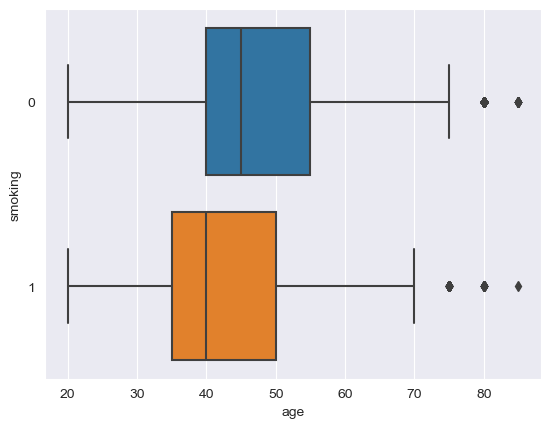


height(cm) statistics: 
Q1: 160.000; Q3: 170.000; lower threshold: 145.000; upper threshold: 185.000


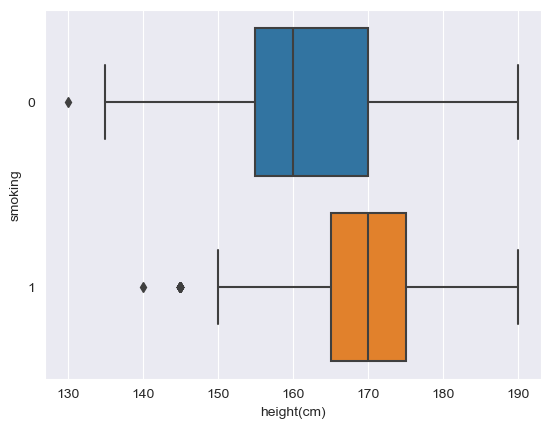


weight(kg) statistics: 
Q1: 55.000; Q3: 75.000; lower threshold: 25.000; upper threshold: 105.000


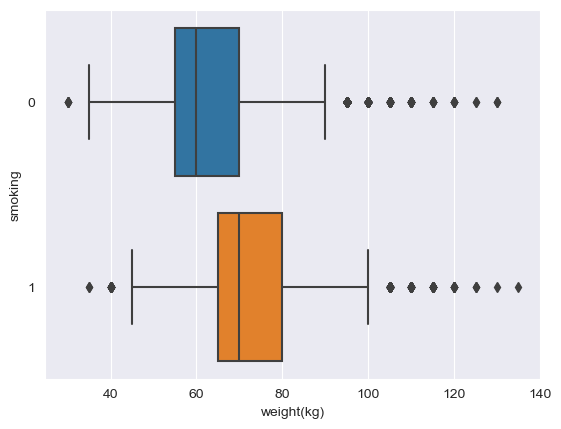


waist(cm) statistics: 
Q1: 76.000; Q3: 88.000; lower threshold: 58.000; upper threshold: 106.000


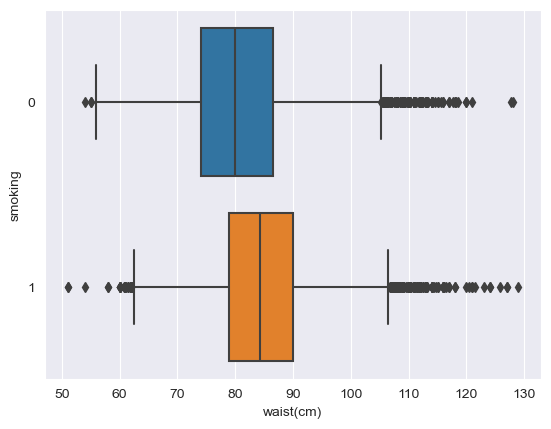


eyesight(left) statistics: 
Q1: 0.800; Q3: 1.200; lower threshold: 0.200; upper threshold: 1.800


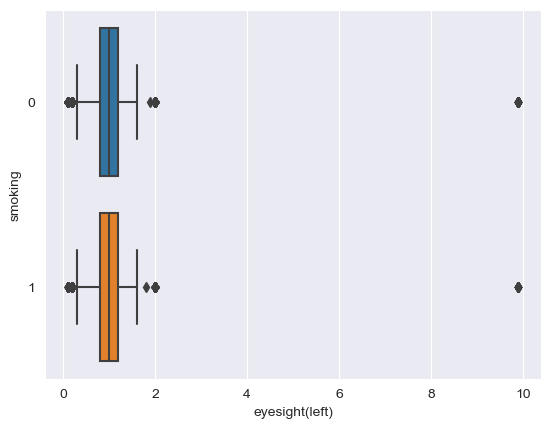


eyesight(right) statistics: 
Q1: 0.800; Q3: 1.200; lower threshold: 0.200; upper threshold: 1.800


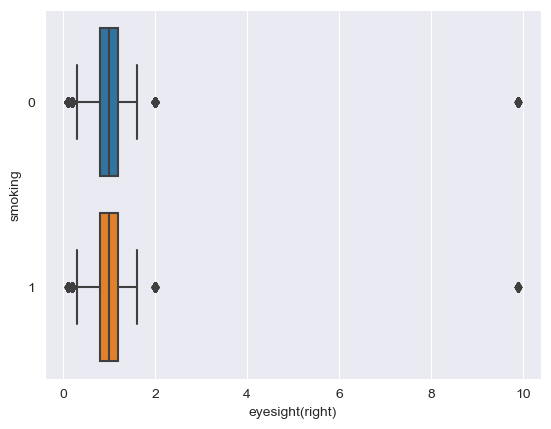


systolic statistics: 
Q1: 112.000; Q3: 130.000; lower threshold: 85.000; upper threshold: 157.000


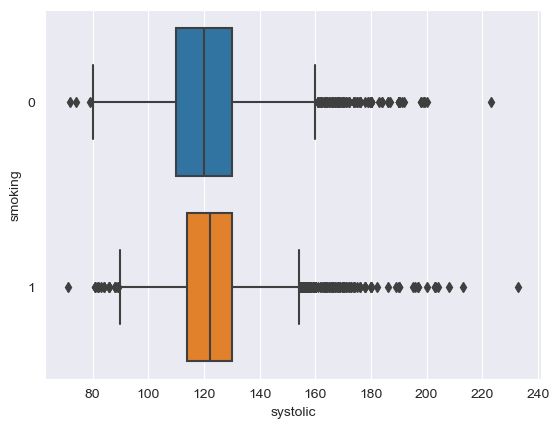


relaxation statistics: 
Q1: 70.000; Q3: 82.000; lower threshold: 52.000; upper threshold: 100.000


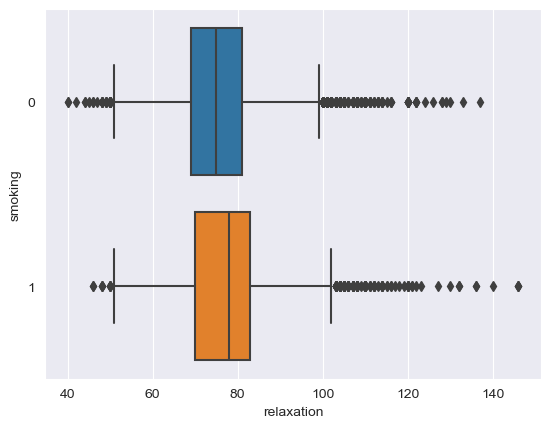


fasting blood sugar statistics: 
Q1: 89.000; Q3: 104.000; lower threshold: 66.500; upper threshold: 126.500


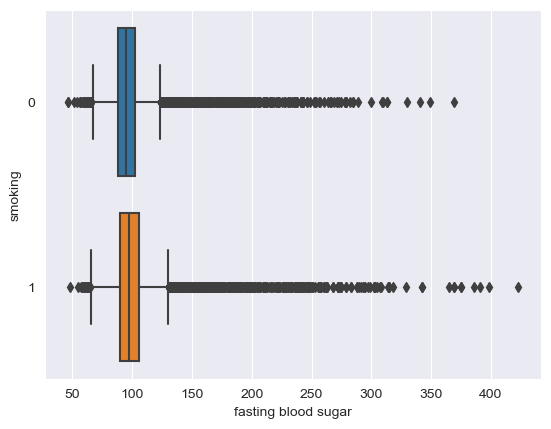


Cholesterol statistics: 
Q1: 172.000; Q3: 219.000; lower threshold: 101.500; upper threshold: 289.500


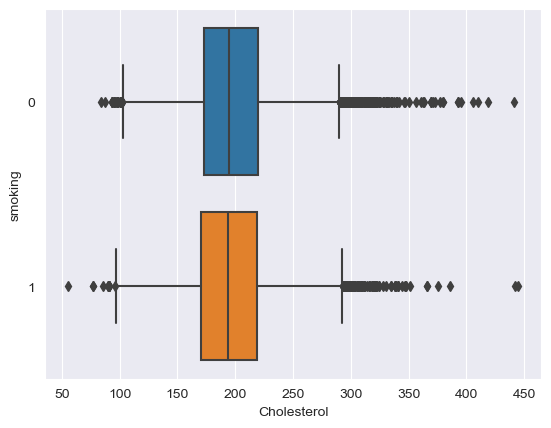


triglyceride statistics: 
Q1: 74.000; Q3: 160.000; lower threshold: -55.000; upper threshold: 289.000


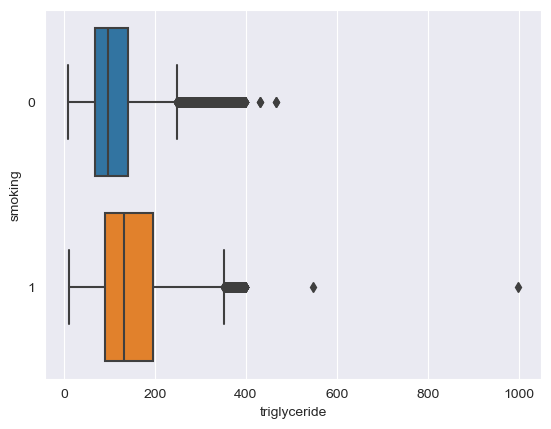


HDL statistics: 
Q1: 47.000; Q3: 66.000; lower threshold: 18.500; upper threshold: 94.500


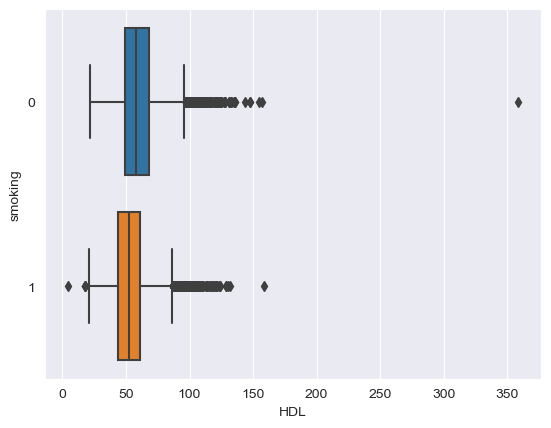


LDL statistics: 
Q1: 91.000; Q3: 136.000; lower threshold: 23.500; upper threshold: 203.500


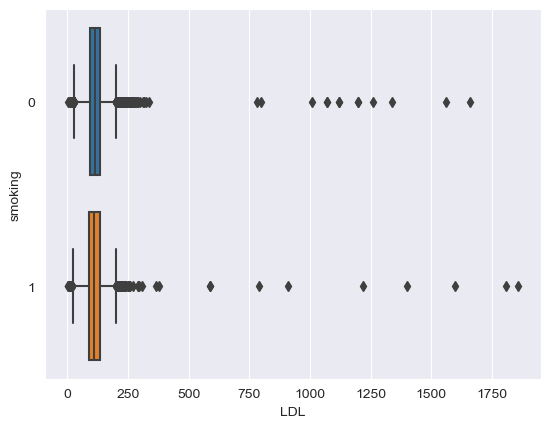


hemoglobin statistics: 
Q1: 13.600; Q3: 15.800; lower threshold: 10.300; upper threshold: 19.100


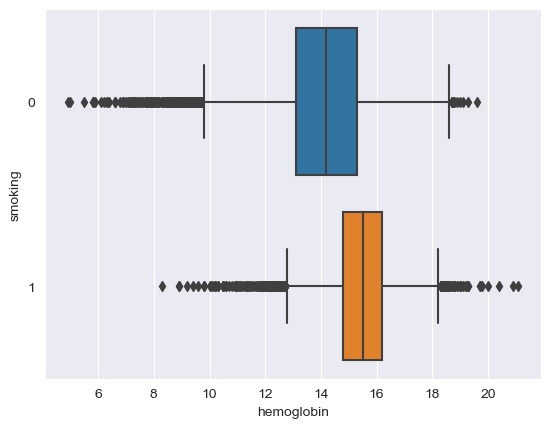


serum creatinine statistics: 
Q1: 0.800; Q3: 1.000; lower threshold: 0.500; upper threshold: 1.300


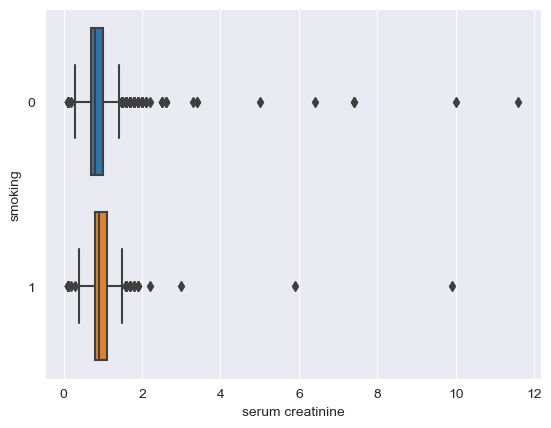


AST statistics: 
Q1: 19.000; Q3: 29.000; lower threshold: 4.000; upper threshold: 44.000


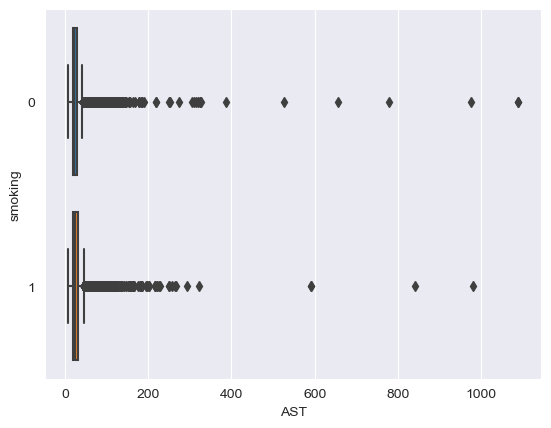


ALT statistics: 
Q1: 15.000; Q3: 31.000; lower threshold: -9.000; upper threshold: 55.000


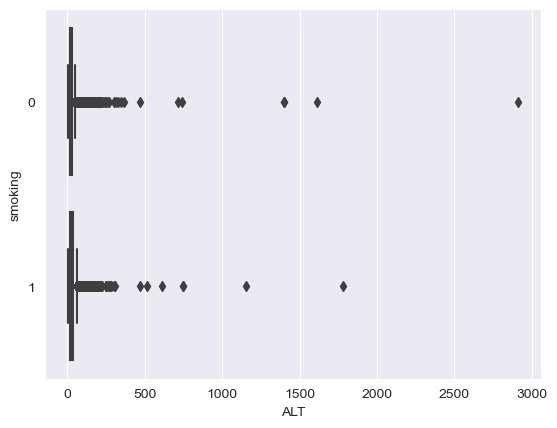


Gtp statistics: 
Q1: 17.000; Q3: 44.000; lower threshold: -23.500; upper threshold: 84.500


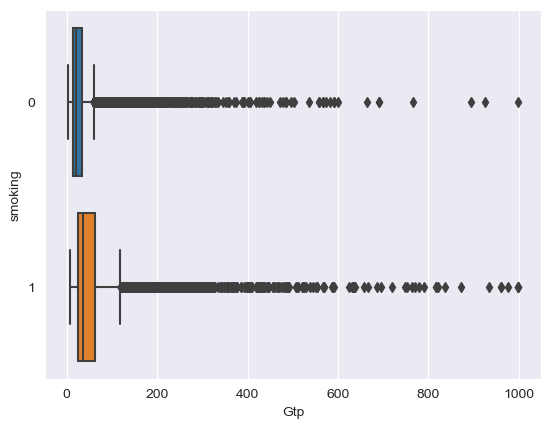

<Figure size 640x480 with 0 Axes>

In [16]:
# Drop categorical features and only keep numerical features
numeric_features = data.drop(cats, axis=1)

# Loop through each column/feature and show information on each feature distribution
for col in numeric_features.columns:
    check_outlier(df, col)

**Task-1: feature discussion (2 pts)**

What understanding, if any, can we gain from looking at the above descriptive statistics? Choose two or three features to comment on.

For example:
from the above descriptive statistics and figures, we can gather some preliminary understanding between the health of smokers and non-smokers. 
- First, we see that smokers tend to weigh more and have larger waists. Together, this implies smokers may be more overweight. 
- Smokers also tend to have higher systolic and relaxtion blood pressures as well as more triglycerides and hemoglobin 
- smokers account for some particularly extreme outliers with regard to triglycerides and hemoglobin. These features are known to be positively correlated with heart disease.

We can also get some insight between the biographic characteristics and smoking habits.
- First, we may find that non-smokers' average age is greater than that of smokers, indicating smokers may have a shorter life.
- Also, we can find that non-smokers tend to have higher height, which cannot by explained by medical knowledge so far. We should be extremely careful with this feature in the following analysis.

For more understanding between the health of smokers and non-smokers, we can see that smokers have lower HDL and more outliers in AST and ALT, which also are correlated with certain disease.

- Check correlation between features

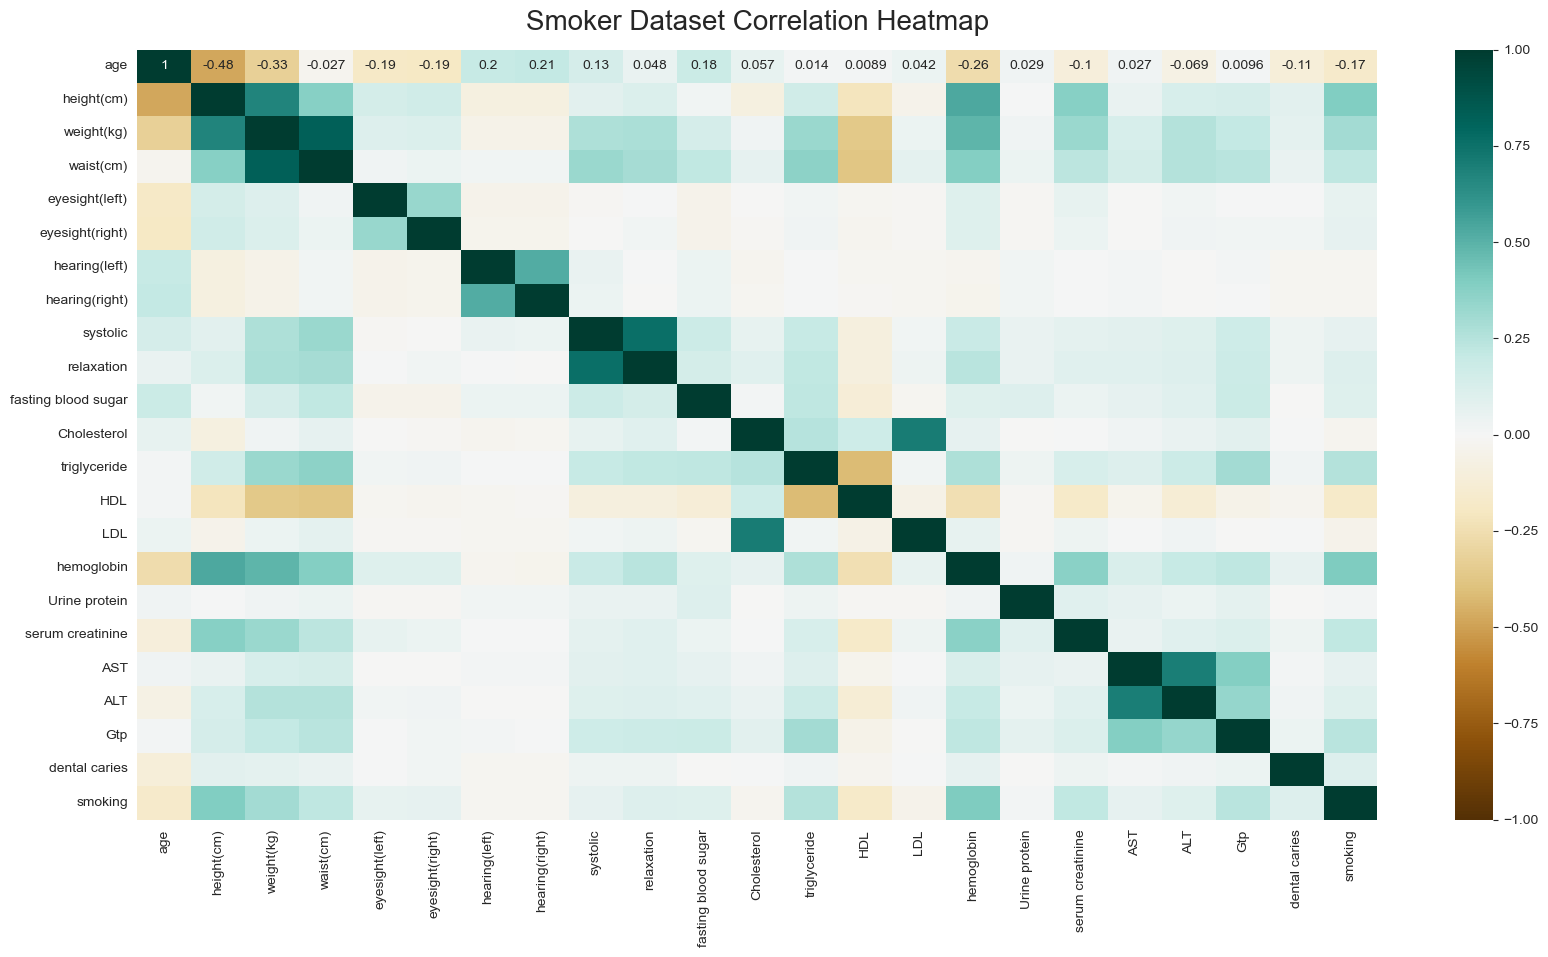

In [17]:
# set the size of the heatmap.
plt.figure(figsize=(20, 10))
heatmap = sns.heatmap(df.corr(), vmin=-1, vmax=1, annot=True, cmap='BrBG')
# Set the title
heatmap.set_title('Smoker Dataset Correlation Heatmap', fontdict={'fontsize':20}, pad=14);

Note, some features are highly correlated, such as weight and waist, systolic and relaxation, and AST and ALT.

**Task-2: model discusion (2pts)**

For the following DT and RF analyses, do we need to take further cleaning steps to account for feature outliers and multicollinearity? Please provide your explaination.


Yes. 
Feature ourliners: Decision tree is sensitive to feature outliners which could lead to the problem of overfitting. While random forest is relatively robust to outliners, extreme outliers can still bias the ensemble predictions. Therefore, it's generally recommended to address outliers.
Multicollinearity: Multicollinearity may not affect the perfomance of DF or RF but may affect the interpretability of the tree, as correlated features may compete for importance, leading to less stable feature importance estimates. And reducing multicollinearity can improve the interpretability of the model.

## Finalize feature and target variables and create train-test split

In [18]:
# Create feature matrix X by concatenating numeric and OHE feature matrix

df_X = pd.concat([numeric_features, ohe_features], axis = 1)

feature_names = df_X.columns.to_list()
df_X.shape

(38984, 30)

In [19]:
# Create target variable
target = 'smoking'
df_y = df[[target]]
df_y.shape

(38984, 1)

In [20]:
# Create split with Sklearn
df_X_train, df_X_test, df_y_train, df_y_test  = train_test_split(df_X, df_y, test_size = 0.3,random_state = 42)

# View the training and testing feature matrix 
df_X_train.shape, df_X_test.shape

((27288, 30), (11696, 30))

# Train and Test DT and RF

In this subsection we will train and test the following models:

i) Decision tree classifier

ii) Random forest classifier

iii) Decision tree regressor



## Decision tree classifier

Fit a decision tree classifier on the training set and evaluate model performance on the testing set (use the *score* function). We will then use feature importance to help us analyze the tree in the context of our data.

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

In [21]:
# Create a DecisionTreeClassifier 
# Please set criterion = "entropy" and random_state = 42, and keep all the other parameters with the default value.
dt_clf = tree.DecisionTreeClassifier(criterion='entropy', random_state=42)
#setting random_state ensures that the random selection of features for splitting nodes is consistent across different runs of the classifier. 

In [22]:
# Use the "fit" function to train the DecisionTreeClassifier on training set
dt_clf.fit(df_X_train, df_y_train)

# Use the "score" function to evaluate the model performance on testing set and report accuracy
# Round it to the 3rd decimal (e.g., 0.800, 0.850, 0.862).
float("{:.3f}".format(dt_clf.score(df_X_test, df_y_test)))

0.737

In [33]:
# Plot the fitted DecisionTreeClassifier. Check: https://scikit-learn.org/stable/modules/tree.html

dtc_data = tree.export_graphviz(dt_clf, out_file=None,
                                feature_names=df_X_train.columns,
                                class_names=None,
                                filled=True, rounded=True,
                                special_characters=True)

graph = graphviz.Source(dtc_data)
graph.render("decision_tree_classifier", format='png', cleanup=True, view=True)

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.23416 to fit


'decision_tree_classifier.png'

Now, explore different parameter settings of the **decision tree classifier** to improve the model performance, i.e., testing score.

E.g., you can try exploring the following hyperparameters: max_depth, min_samples_split, and min_samples_leaf.

Briefly discuss what you find and how it relates to what we learned about the pros and cons of decision trees. If you are unable to improve the score, also try to connect and explain based on what we learned in class.

In [120]:
# here is an example of setting max_depth=30 
dt_clf2 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=30)

# fit the model
dt_clf2.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf2.score(df_X_test, df_y_test)))

0.737

In [122]:
# setting max_depth=100
dt_clf3 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, max_depth=100)

# fit the model
dt_clf3.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf3.score(df_X_test, df_y_test)))

0.737

In [123]:
# setting min_samples_split=3
dt_clf4 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_split=3)

# fit the model
dt_clf4.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf4.score(df_X_test, df_y_test)))

0.738

In [124]:
# setting min_samples_split=10
dt_clf5 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_split=10)

# fit the model
dt_clf5.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf5.score(df_X_test, df_y_test)))

0.725

In [125]:
# setting min_samples_leaf=10
dt_clf6 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_leaf=10)

# fit the model
dt_clf6.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf6.score(df_X_test, df_y_test)))

0.713

In [36]:
# setting min_samples_leaf=50
dt_clf7 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_leaf=50)

# fit the model
dt_clf7.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf7.score(df_X_test, df_y_test)))

0.726

In [37]:
# setting min_samples_leaf=2
dt_clf8 = tree.DecisionTreeClassifier(criterion='entropy', random_state=42, min_samples_leaf=2)

# fit the model
dt_clf8.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_clf8.score(df_X_test, df_y_test)))

0.731

**Task-3: model parameter exploration and discussion (2 pts)**

For an example: in the above exploration, results show that:
- Setting max_depth=30 helps increase accuracy by .3 percentage points. 
- The score is fairly robust to changes of max_depth.

max depth:
- Setting max_depth=30 helps increase accuracy by .3 percentage points.
- The score is fairly robust to changes of max_depth.
- As the max_depth increase largely(such as 100), the accuracy may fall, which could be considered as a result of overfitting.

min_samples_split
- Increasing the min_samples_split to 3 increases accuracy by .1 percentage points, while increasing more(for example, to 10) conversely decreases the testing score, also may be resulted from overfitting.

min_samples_leaf
- The performance firstly decrease sharply with the increase of the min_samples_leaf, and then increase slowly but not as high as when min_samples_leaf=1. This might also be a result of overfitting. In this specific dataset, the defalt value of min_samples_leaf=1 might be an optimal choice.

Now pick the best decision tree classifier you just explored, we will use the decision tree model's [**feature importance**](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier.feature_importances_) attribute to interpret the results (features are ranked by the total reduction of the criterion (e.g., gini or entropy))

In [27]:
# extract feature names of best performing model
features = dt_clf2.feature_names_in_
# extract feature importance
importance = np.round(dt_clf2.feature_importances_,2)

# Create pandas dataframe of feature and correpsonding importance
df_importance = pd.DataFrame([features, importance]).T
df_importance.rename(columns={0: 'feature', 1:'importance'}, inplace=True)

# Sort descendingly based on importance
df_importance.sort_values(['importance'], ascending=False, inplace=True)

# Show dataframe
df_importance.reset_index(drop=True)

,feature,importance
0,height(cm),0.16
1,hemoglobin,0.1
2,Gtp,0.09
3,triglyceride,0.07
4,waist(cm),0.05
5,ALT,0.05
6,systolic,0.05
7,fasting blood sugar,0.05
8,Cholesterol,0.05
9,HDL,0.05


**Discussion**

In the above dataset, "importance" contains the importance values for each "feature" used in the decision tree. In particular, for each feature, importance is the sum of the reduction in uncertainty/impurity for each node on which the feature is split. For more information on feature importance, see https://towardsdatascience.com/feature-importance-in-decision-trees-e9450120b445.

What can we take away from the above results?

The feature which explains the most variation, i.e., results in the largest decrease in uncertainty, is height. This is unexpected given what we know about the attributes of smokers, and may be an anamoly within this specific sample. The next few features are hemoglobin, Gtp, triglyceride, HDL, and systolic. This is more in line with what we would expect given our preliminary analysis which showed that smokers tended to have higher hemoglobin, triglyceride, and fasting blood sugar levels. It provides additional evidence that these features are related to whether an individual smokes, since splitting on them gives us relatively more information on classifying smokers (our target variable).

Any caveats?

From class, we know that decision trees are sensitive to data, and a few additional samples can cause the model to pick different features that lead to different tree structures. Hence, this single analysis cannot be considered robust without further samples.

## Your free exploration (optional)
In the above sections, we conduct the following data processing for the features:
- for categorical features, we do one-hot encoding
- for numerical features, we explored the outlier distribution and multicollinearity, without any further process

In this section, you will do some free exploration to see how does the following change affect model performance:
- for categorical features, whether it is necessary to encode them? Try your experiment of **not encode** categorical features and check how this affect the model performance?
- for numerical features, whether it is necessary to remove outliers? Try your experiment of **removing outliers based on your understanding** and check how this affect the model performance?

In your exploration, please write comments to explain your code, and provide a discussion of the results (the same style as we provided in this jupyter notebook).

## Random forest classifier

In the previous task, we explored different data processing steps to clean data and improve the performance of a decision tree classifier.

In this task, you will use the same data to:
- train a [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).
- report its performance on the test set
- compare the performance of a decision tree classifier and a random forest classifier

In [28]:
# Instantiate the model
rf_clf = RandomForestClassifier(n_estimators = 100, criterion = 'entropy', random_state = 42)

# train RFC
rf_clf.fit(df_X_train, df_y_train['smoking'])

# evaluate the random forest classifier on test set 
float("{:.3f}".format(rf_clf.score(df_X_test, df_y_test['smoking'])))

0.796

Let's now extract the feature importance as earlier.

In [29]:
# extract feature names of initial model
features = rf_clf.feature_names_in_
# extract feature importance
importance = np.round(rf_clf.feature_importances_,2)

# Create pandas dataframe of features and correpsonding importance
df_importance = pd.DataFrame([features, importance]).T
df_importance.rename(columns={0: 'feature', 1:'importance'}, inplace=True)

# Sort descendingly based on importance
df_importance.sort_values(['importance'], ascending=False, inplace=True)

# Show dataframe
df_importance.reset_index(drop=True)

,feature,importance
0,hemoglobin,0.11
1,Gtp,0.09
2,height(cm),0.09
3,triglyceride,0.07
4,waist(cm),0.05
5,ALT,0.05
6,systolic,0.05
7,fasting blood sugar,0.05
8,Cholesterol,0.05
9,HDL,0.05


**Task-4 (2 pts): compare DT and RF**

- What are your thoughts after comparing decision tree classifier and random forest classifier? 
- Do the feature importance results make more sense within the context of the data? 
- Can any conclusions drawn from the importance be considered more robust than those from the decision we considered earlier? If so, why?   


1. Based on the testing score, the random forest classifier performs better in the test data than the decision tree classifier. The reasons could be:
1) Random Forest Classifier typically provides higher accuracy compared to a single decision tree classifier, especially for complex datasets, because it combines the predictive power of multiple decision trees to improve overall performance while the decision tree classifier's performance may be limited.
2) Random Forest Classifier combats overfitting by averaging predictions from multiple decision trees trained on different subsets of the data, while Decision Tree Classifier often prone to overfitting, especially when the tree is deep or when the dataset is complex as it tends to capture noise in the data and may not generalize well to unseen data.

2. Yes. In the feature importance resulting from the decision tree classifier, 'height' ranks as the first. However, height may not be related to one's smoking or not, at least not a priority consideration. As in the feature importance from the random forest classifier, the 'height' falls to the third place, which makes more sense. And other health index which is correlated to deseases related to smokig still ranks high.

3. Yes
- Random Forest aggregates predictions from multiple decision trees trained on different subsets of the data. Each decision tree in the forest may have a slightly different view of the importance of features. By averaging these importance scores across multiple trees, Random Forest reduces the variability and uncertainty associated with feature importance estimates. This averaging effect provides a more stable and reliable estimate of feature importance compared to a single Decision Tree.
- Decision Trees are prone to overfitting, which can lead to unreliable estimates of feature importance. Random Forest, on the other hand, mitigates overfitting by training multiple trees on different subsets of the data and averaging their predictions. This reduction in overfitting helps to prevent the dominance of noise or outliers in determining feature importance, leading to more robust conclusions.

## Decision tree regressor

- Please follow the logic of building a decision tree classifier to build a decision tree regressor using a numeric variable as the target.
- Let's take "age", a continuous value, as the new target variable for a regression task. i.e., predict an individual's age based on biological features
- Visualize to show how decision tree regressor is different from decision tree classifier.
- Decision tree regressor: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html

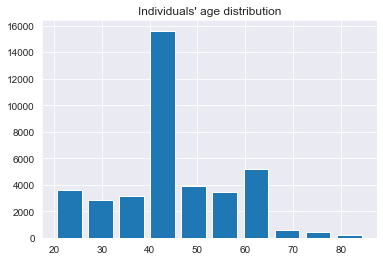

In [30]:
# Explore the target variable "age"
plt.hist(df_X['age'], rwidth=0.8);
plt.title("Individuals' age distribution");

In [31]:
# Create new train and test data with age as the target
df_X_reg = df_X.drop(['age'], axis=1)
print(f'Shape of X: {df_X_reg.shape}')

# Create target variable
target = 'age'
df_y_reg = df_X[[target]]
print(f'Shape of y: {df_y_reg.shape}')


# Create split with sklearn
df_X_train_reg, df_X_test_reg, df_y_train_reg, df_y_test_reg  = train_test_split(df_X_reg, df_y_reg, test_size = 0.2, random_state = 42)

# View feature matrix 
print(f'Shape of data (X train, X test): {df_X_train_reg.shape, df_X_test_reg.shape}')


Shape of X: (38984, 29)
Shape of y: (38984, 1)
Shape of data (X train, X test): ((31187, 29), (7797, 29))


In [25]:
# Instantiate a decision tree regressor with parameters: criterion="squared_error", random_state=42, max_depth=7
# fit and evaluate the model
dt_reg = tree.DecisionTreeRegressor(criterion="squared_error", random_state=42, max_depth=7)

# fit the model
dt_reg.fit(df_X_train, df_y_train)

# evaluate the model
float("{:.3f}".format(dt_reg.score(df_X_test, df_y_test)))


0.262

In [26]:
mse = dt_reg.score(df_X_test, df_y_test)
print("R^2 Score:", mse)

R^2 Score: 0.26163087931494744


In [32]:
#### Plot the fitted DecisionTreeRegressor
dtr_data = tree.export_graphviz(dt_reg, out_file=None,
                                feature_names=df_X_train.columns,
                                class_names=None,
                                filled=True, rounded=True,
                                special_characters=True)

graph = graphviz.Source(dtr_data)
graph.render("decision_tree_regressor", format='png', cleanup=True, view=True)


'decision_tree_regressor.png'

**Task-5 (2 pts): compare classifier and regressor**

Briefly describe the differences between the decision tree classifier and regressor. Mention any differences found by comparing the tree visualizations.


1. Output type: A decision tree classifier is used when the output variable is categorical, while a decision tree regressor is used when the output variable is continuous.
2. Performance evaluation: Decision tree regressors typically use the mean squared error (MSE) as their impurity metric, while decision tree classifiers typically use entropy or the Gini index for performance evaluation.

3. comparing the tree visualizations:
1) Decision tree classifier tend to have more splits than decision tree classifier regressor, which may be due to that decision tree classifier are partitioning feature space into regions corresponding to different classes while decision trees regressor are trying to capture the overall trend of the continuous target variable.
2) (In this case,) Decision tree classifier tend to have an unbalnaced tree(the depth of each leaf is different), while the decision tree regressor has a balanced tree(the depth of each leaf is the same).

# Conclusion

In this assignment, we predict individual's smoking status based on biological features. 
- In particular, we modeled the relationship between these features and smoking status with two tree-based classifiers, attaining a fairly accurate result. 
- Furthermore, we utilized the properties of the classifers to gain a better understanding of which features contributed the most to differentiating smokers and non smokers. 
- Interpreting these results within the context of the data, i.e., the information provided by the dataset and our prior knowledge of the health impacts of smoking, allowed us to better understand the biological mechanisms through which smoking causes harm, heart disease in particular. 
- Additionally, comparing the decision tree and random forest classifiers shed light on how each model's pros and cons can impact the robustness of results.